# 04 · Evaluation

We evaluate in two ways:

1. **4-fold cross-validation by recording** on the 65 training recordings. Each fold holds
   out 3–5 recordings of every activity (15–18 in total), and the model (scaler + HMM) is
   trained on the other 47–50. Every window is predicted by a model that never saw its
   recording, and each held-out recording is decoded with Viterbi as its own sequence.
2. **Unseen test data**: two new ~60 s recordings from a separate session, each containing
   several activities in a row. The model is trained once on all 65 training recordings
   and never sees these files before testing.

In [1]:
# --- Environment setup (works locally and in Google Colab) ---
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/Orrie-Dan/Human-Activity-HMM.git"
    ROOT = Path("/content/human-activity-hmm")
    if not ROOT.exists():
        !git clone -q {REPO_URL} {ROOT}
    %cd {ROOT}
    !pip install -q -r requirements.txt
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# The recordings are in the repository (data/raw/, data/test/). Fallback only: if
# data/raw/ is empty in Colab, upload a zip of its contents (p01_<activity>_<nn>/ + metadata.csv).
RAW = ROOT / "data" / "raw"
if IN_COLAB and not any(RAW.glob("p*_*_*")):
    import io, zipfile
    from google.colab import files
    for name, content in files.upload().items():
        zipfile.ZipFile(io.BytesIO(content)).extractall(RAW)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import apply_style

apply_style()
pd.set_option("display.precision", 3)

from src.features import add_magnitudes


In [3]:
from src.dataset import build_feature_table

if config.FEATURES_FILE.exists():
    table = pd.read_csv(config.FEATURES_FILE)
else:  # build it if notebook 02 has not been run
    table, _ = build_feature_table()
    config.FEATURES_FILE.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(config.FEATURES_FILE, index=False)
print(f"{len(table)} windows from {table['recording'].nunique()} recordings")


462 windows from 65 recordings


## Predictions on held-out data

In [4]:
from src.training import cross_validate, recording_folds

for i, fold in enumerate(recording_folds(table, config.DEFAULT_HMM_CONFIG.n_folds)):
    print(f"fold {i}: test = {fold}")
results = cross_validate(table)
results.head()

fold 0: test = ['p01_jumping_01', 'p01_jumping_05', 'p01_jumping_09', 'p01_jumping_13', 'p01_standing_01', 'p01_standing_05', 'p01_standing_09', 'p01_standing_13', 'p01_still_01', 'p01_still_05', 'p01_still_09', 'p01_still_13', 'p01_still_17', 'p01_walking_01', 'p01_walking_05', 'p01_walking_09', 'p01_walking_13', 'p01_walking_17']
fold 1: test = ['p01_jumping_02', 'p01_jumping_06', 'p01_jumping_10', 'p01_standing_02', 'p01_standing_06', 'p01_standing_10', 'p01_standing_14', 'p01_still_02', 'p01_still_06', 'p01_still_10', 'p01_still_14', 'p01_still_18', 'p01_walking_02', 'p01_walking_06', 'p01_walking_10', 'p01_walking_14']
fold 2: test = ['p01_jumping_03', 'p01_jumping_07', 'p01_jumping_11', 'p01_standing_03', 'p01_standing_07', 'p01_standing_11', 'p01_standing_15', 'p01_still_03', 'p01_still_07', 'p01_still_11', 'p01_still_15', 'p01_still_19', 'p01_walking_03', 'p01_walking_07', 'p01_walking_11', 'p01_walking_15']
fold 3: test = ['p01_jumping_04', 'p01_jumping_08', 'p01_jumping_12', 

,recording,participant,activity,window_index,window_start_s,fold,supervised,baum_welch
0,p01_jumping_01,p01,jumping,0,0.0,0,jumping,jumping
1,p01_jumping_01,p01,jumping,1,0.5,0,jumping,jumping
2,p01_jumping_01,p01,jumping,2,1.0,0,jumping,jumping
3,p01_jumping_01,p01,jumping,3,1.5,0,jumping,jumping
4,p01_jumping_01,p01,jumping,4,2.0,0,jumping,jumping


## Metrics and confusion matrix

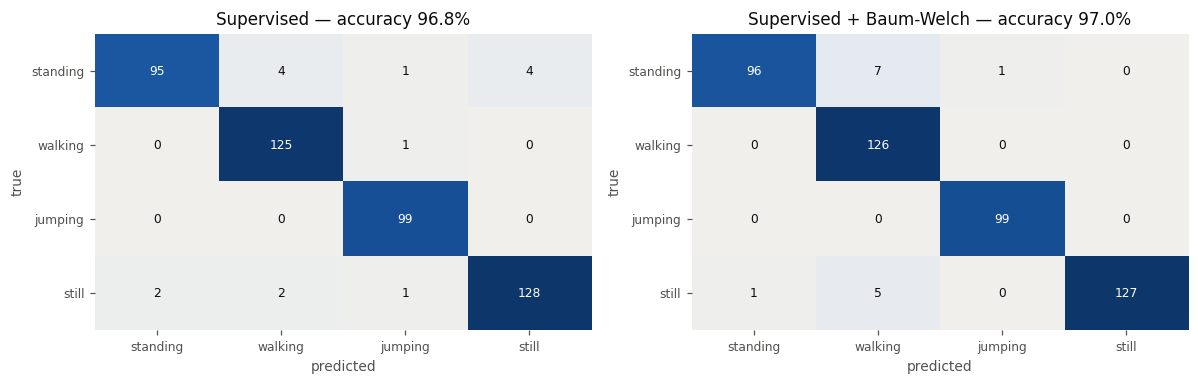

In [5]:
from src.evaluation import evaluate
from src.visualization import plot_matrix

VARIANTS = {"supervised": "Supervised", "baum_welch": "Supervised + Baum-Welch"}
metrics = {v: evaluate(results["activity"], results[v], config.ACTIVITIES) for v in VARIANTS}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (v, title) in zip(axes, VARIANTS.items()):
    plot_matrix(metrics[v]["confusion"], f"{title} — accuracy {metrics[v]['accuracy']:.1%}",
                fmt="{:.0f}", ax=ax, xlabel="predicted", ylabel="true")
fig.tight_layout()

In [6]:
pd.concat({VARIANTS[v]: m["per_class"] for v, m in metrics.items()}, axis=1)

Supervised                                       \
         sensitivity specificity precision     f1 support   
true                                                        
standing       0.913       0.994     0.979  0.945     104   
walking        0.992       0.982     0.954  0.973     126   
jumping        1.000       0.992     0.971  0.985      99   
still          0.962       0.988     0.970  0.966     133   

         Supervised + Baum-Welch                                       
                     sensitivity specificity precision     f1 support  
true                                                                   
standing                   0.923       0.997     0.990  0.955     104  
walking                    1.000       0.964     0.913  0.955     126  
jumping                    1.000       0.997     0.990  0.995      99  
still                      0.955       1.000     1.000  0.977     133

Accuracy per held-out recording (only recordings with any error are shown):

In [7]:
per_recording = pd.DataFrame({
    v: (results["activity"] == results[v]).groupby(results["recording"]).mean() for v in VARIANTS
})
per_recording[(per_recording < 1).any(axis=1)]

,supervised,baum_welch
recording,,
p01_standing_01,0.500,0.600
p01_standing_05,0.750,0.000
p01_standing_07,0.250,1.000
p01_still_01,0.778,0.778
p01_still_02,0.846,0.769
p01_still_05,0.750,0.750
p01_walking_03,0.929,1.000


### Where the errors happen

Viterbi paths for the recordings with errors (gray band = true activity, dots = prediction):

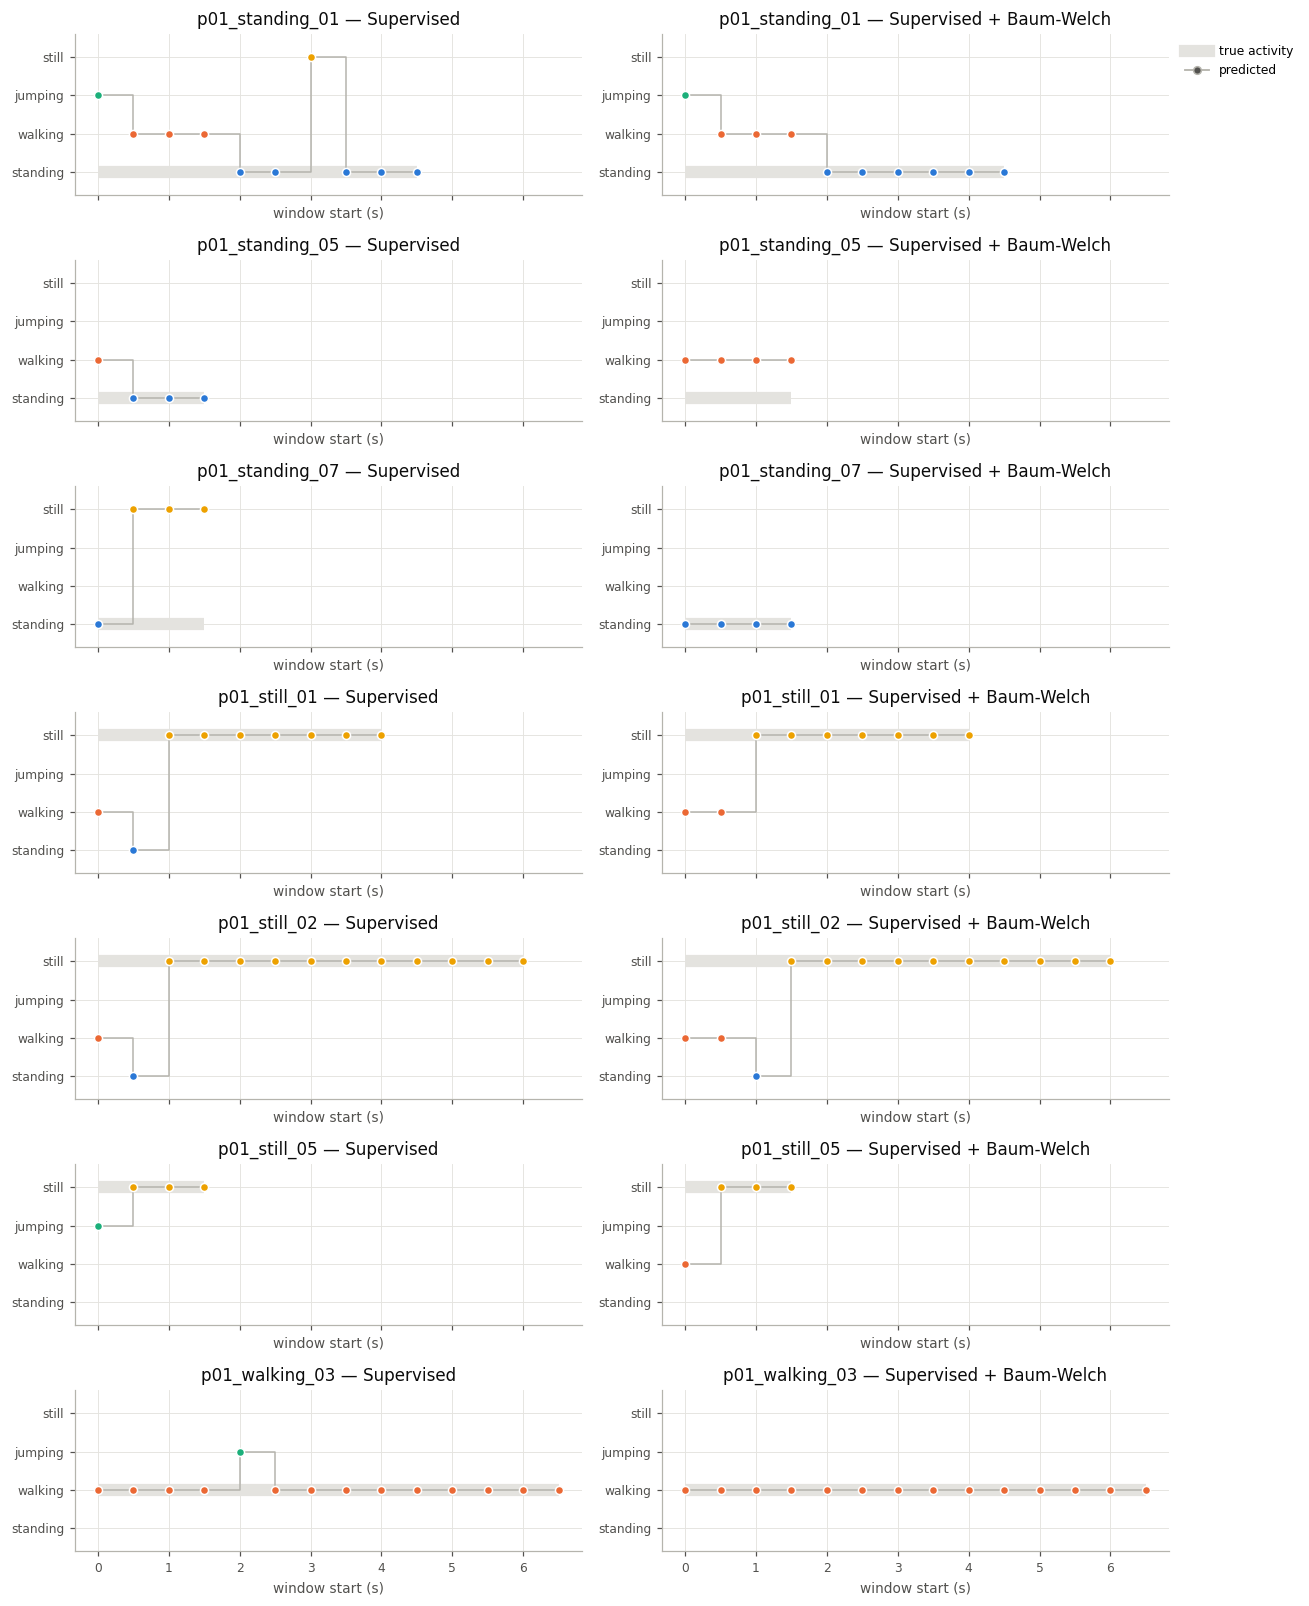

In [8]:
from src.visualization import plot_decoded

names = per_recording[(per_recording < 1).any(axis=1)].index.tolist()
fig, axes = plt.subplots(len(names), 2, figsize=(12, 2.1 * len(names)), sharex=True)
for row, name in enumerate(names):
    seq = results[results["recording"] == name].sort_values("window_index")
    for col, (v, title) in enumerate(VARIANTS.items()):
        plot_decoded(seq["window_start_s"], seq["activity"], seq[v], f"{name} — {title}",
                     ax=axes[row, col], legend=(row == 0 and col == 1))
fig.tight_layout()

## Evaluation on unseen data

Cross-validation reuses recordings from the same sessions. For a real test, we recorded **two new
files in a separate session** (1 Nov, 16:03 and 16:05), after all training data had been collected.
They are stored apart from the training data in `data/test/` and are **never used for training,
scaling or model selection**.

Unlike the training recordings, each test file is a **continuous ~60 s recording with several
activities in a row**, including the real transitions between them (picking the phone up from the
table, starting to jump, stopping). So it also tests whether the transition model can follow
real changes of activity:

| File | Duration | Activity order |
|---|---|---|
| `p01_mixed_01` | 62 s | walking → still → jumping → standing → still → walking |
| `p01_mixed_02` | 64 s | still → jumping → walking → standing → walking |

The segment boundaries are in `data/test/labels.csv`. The time between segments is handling and is
left unlabeled. Each 2 s window that lies fully inside one segment gets that activity. Windows that
overlap a boundary are labeled *transition*: they are decoded as part of the sequence but **not
scored**. The test recordings are not trimmed, and they go through the same 50 Hz resampling and
feature extraction as the training data.

activity,jumping,standing,still,transition,walking,All
recording,,,,,,
p01_mixed_01,14,11,28,32,36,121
p01_mixed_02,12,17,27,21,48,125
All,26,28,55,53,84,246


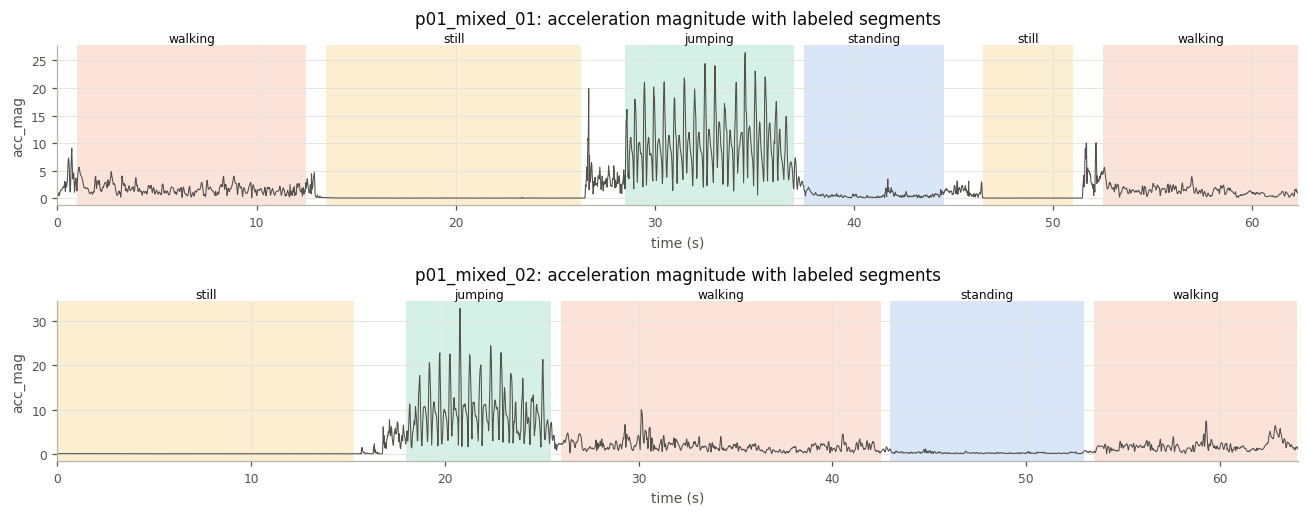

In [9]:
from src.test_set import build_test_table, load_labels, TEST_RECORDING_CONFIG
from src.dataset import process_recording
from src.visualization import plot_test_timeline

test = build_test_table()
test.to_csv(config.TEST_FEATURES_FILE, index=False)
labels = load_labels()
fig, axes = plt.subplots(2, 1, figsize=(12, 4.8))
for ax, (name, segs) in zip(axes, labels.groupby("recording")):
    sig = add_magnitudes(process_recording(config.TEST_DATA_DIR / name, TEST_RECORDING_CONFIG))
    plot_test_timeline(sig, segs, f"{name}: acceleration magnitude with labeled segments", ax=ax)
fig.tight_layout()
pd.crosstab(test["recording"], test["activity"], margins=True)

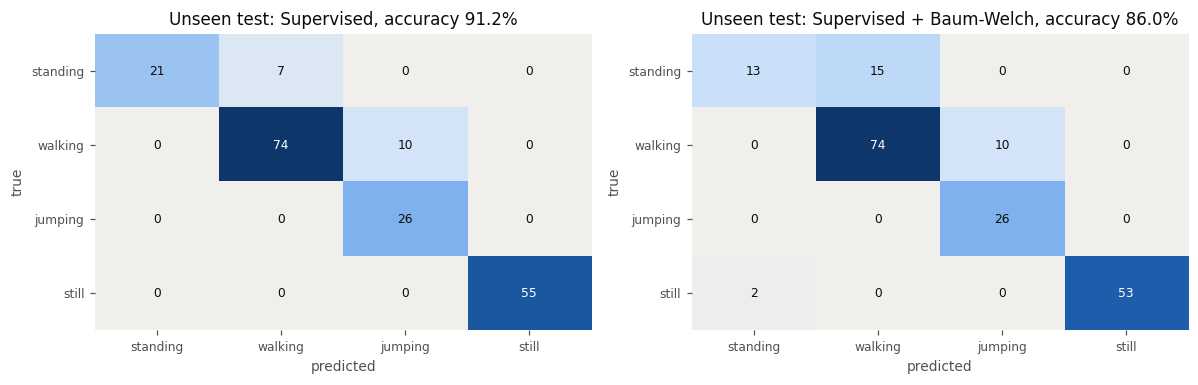

In [10]:
from src.training import predict_unseen, scored_windows
from src.evaluation import report_table

test_results, test_models = predict_unseen(table, test)
scored = scored_windows(test_results)
test_metrics = {v: evaluate(scored["activity"], scored[v], config.ACTIVITIES) for v in VARIANTS}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (v, title) in zip(axes, VARIANTS.items()):
    plot_matrix(test_metrics[v]["confusion"], f"Unseen test: {title}, accuracy {test_metrics[v]['accuracy']:.1%}",
                fmt="{:.0f}", ax=ax, xlabel="predicted", ylabel="true")
fig.tight_layout()

Results table on the unseen test windows (accuracy per activity is one-vs-rest, $(TP+TN)/N$):

In [11]:
pd.concat({VARIANTS[v]: report_table(m["confusion"]) for v, m in test_metrics.items()}, axis=1).round(3)

Supervised                                   \
                 Number of samples Sensitivity Specificity Accuracy   
State (activity)                                                      
standing                        28       0.750       1.000    0.964   
walking                         84       0.881       0.936    0.912   
jumping                         26       1.000       0.940    0.948   
still                           55       1.000       1.000    1.000   
Overall                        193         NaN         NaN    0.912   

                 Supervised + Baum-Welch                                   
                       Number of samples Sensitivity Specificity Accuracy  
State (activity)                                                           
standing                              28       0.464       0.988    0.912  
walking                               84       0.881       0.862    0.870  
jumping                               26       1.000       0.940    0.948  
still                                 55       0.964       1.000    0.990  
Overall                              193         NaN         NaN    0.860

Decoded Viterbi paths for both test recordings (gray band = true activity, gaps = transition windows):

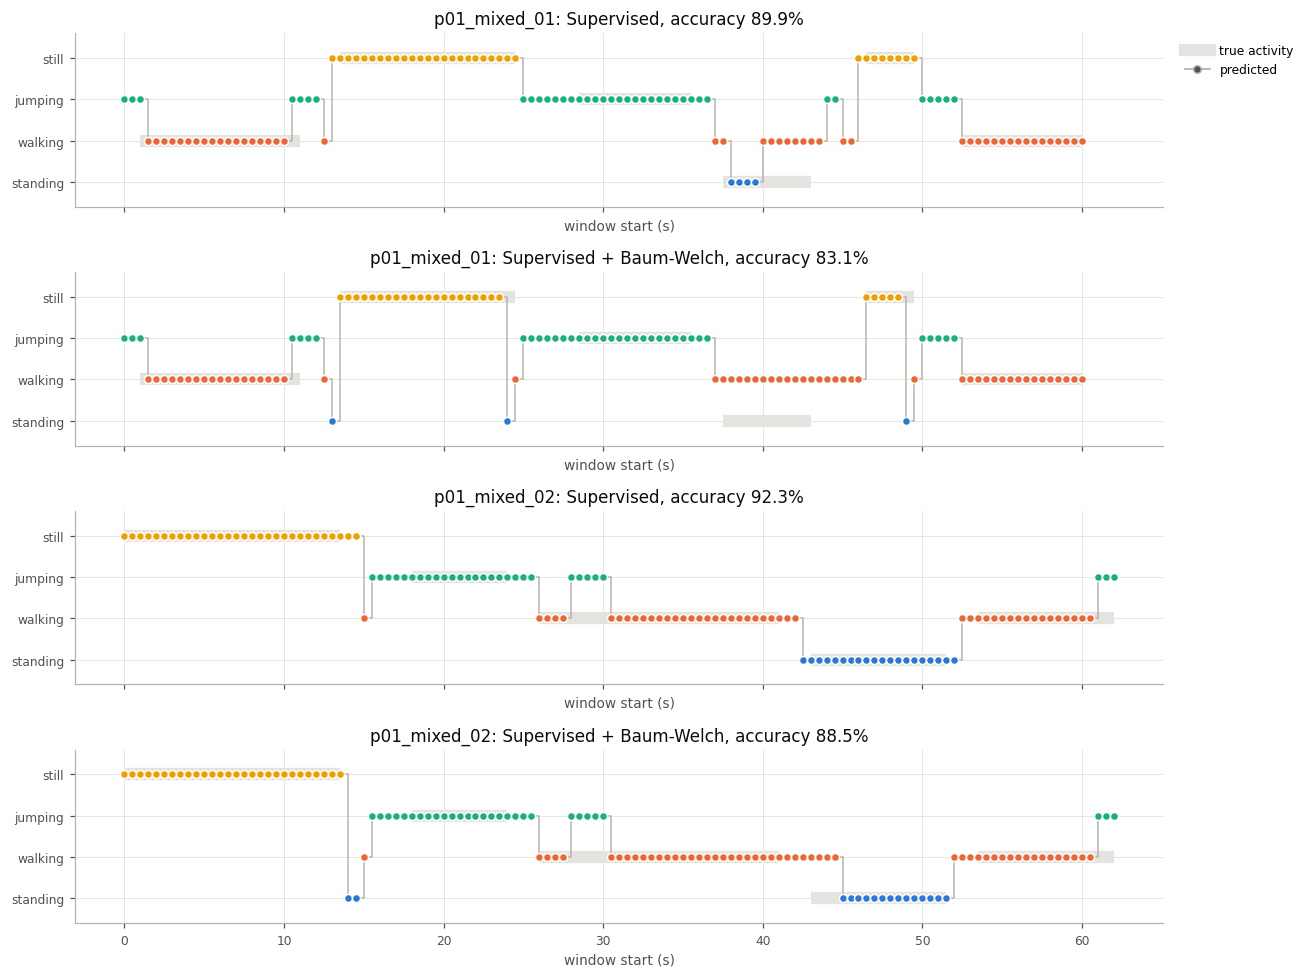

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
row = 0
for name, seq in test_results.groupby("recording"):
    seq = seq.sort_values("window_index")
    for v, title in VARIANTS.items():
        s = scored_windows(seq)
        acc = (s["activity"] == s[v]).mean()
        plot_decoded(seq["window_start_s"], seq["activity"], seq[v],
                     f"{name}: {title}, accuracy {acc:.1%}", ax=axes[row], legend=(row == 0))
        row += 1
fig.tight_layout()

**How well does the model generalize?** On the unseen recordings the supervised model labels
**91.2 %** of the 193 scored windows correctly (89.9 % and 92.3 % for the two files). That is
about 6 points below cross-validation (96.8 %), which is the drop we expected: the test
recordings were made in a different session, and they include real activity changes, which
the training data never contained.

- **Still** is perfect (55/55) and **jumping** is never missed (26/26). Both are at the
  extremes of movement intensity.
- **Every one of the 9 real activity changes is detected**, usually within one or two windows
  of the labeled boundary, even though the transition matrix was never trained on a real
  change.
- **Walking → jumping (10 windows)**: 5 come from a burst around 28–30 s in `p01_mixed_02`,
  where the acceleration jumps to about 10 m/s² (most likely a turn or stumble). 3 come from
  the last second of that file, when the phone is lifted to stop the recording, and 2 from the
  edges of the first walking segment.
- **Standing → walking (7 windows)**: all in `p01_mixed_01`, around 40–43 s. The signal shows
  a short movement there (a hand adjustment). With only 7 s of standing in that file, this
  costs most of the segment.
- **Transition windows** (not scored) are mostly decoded as *jumping*. Picking the phone up
  from the table produces short spikes, and among our four states jumping explains spikes best.
  A fifth "handling" state would be needed to model this.

**Baum-Welch does worse on unseen data** (86.0 % vs 91.2 %), although it was slightly better in
cross-validation (97.0 % vs 96.8 %). It loses most standing windows to walking: EM re-estimates
the variances on the training sessions only, which shrinks standing's variance, so the slightly
more active standing in the new session no longer fits. We therefore use the **supervised model**
as our final model. This is the main lesson of the unseen test: a model that fits its own
sessions better is not necessarily the one that generalizes better.

## Transition/emission analysis

How much do transitions matter compared with emissions? For each window we compare the
best and second-best state's emission log-likelihood. A switch costs about
$\log(A_{kk}/A_{kj}) = \log(0.97/0.01) \approx 4.6$ nats in the supervised model. Only windows
whose emission gap is smaller than that can be changed by the transition matrix.

In [13]:
from src.training import train_model

model = train_model(table)
X = model.scaler.transform(table[model.feature_columns].to_numpy(dtype=float))
log_b = np.sort(model.hmm.log_emission(X), axis=1)
gap = log_b[:, -1] - log_b[:, -2]
A = model.hmm.transmat
switch_cost = np.log(np.diag(A).mean() / A[~np.eye(len(A), dtype=bool)].mean())
print(f"switch cost: {switch_cost:.1f} nats")
print(f"emission gap between best and 2nd-best state: median {np.median(gap):.0f} nats, "
      f"10th percentile {np.percentile(gap, 10):.1f}")
print(f"windows where transitions can change the decision (gap < cost): {(gap < switch_cost).mean():.1%}")

switch cost: 4.6 nats
emission gap between best and 2nd-best state: median 169 nats, 10th percentile 45.0
windows where transitions can change the decision (gap < cost): 0.9%


Emissions dominate. The median gap is about 170 nats, roughly 37 times the switch cost, and only
4 of 462 windows (0.9 %) are close enough for the transition matrix to change the decision. So the
HMM behaves almost like a per-window Gaussian classifier, and the transitions only smooth a
handful of borderline windows. This is a consequence of using 56 features, each adding its own
term to the log-likelihood.

These gaps are measured on the training data (model fitted on all windows). On unseen windows
they are smaller, so transitions matter more there. In the test recordings the high
self-transition probability (0.97) is what keeps single noisy windows from flipping the state.

## Discussion

**Results.**

| Evaluation | Supervised | Supervised + Baum-Welch |
|---|---|---|
| 4-fold CV, 65 recordings, 462 windows | 96.8 % | 97.0 % |
| Unseen test, 2 recordings, 193 scored windows | **91.2 %** | 86.0 % |

**Easiest and hardest activities.** Jumping and still are easiest: in cross-validation jumping
reaches sensitivity 1.00, and on the unseen data both are perfect. Standing is hardest. It
lies between still (no movement) and walking (much movement), so any disturbance pushes it
to one side: a bump or hand adjustment makes it look like walking, and very quiet standing
looks like still. Its sensitivity is 0.91 in CV and 0.75 on the unseen data.

**More data helped.** With 16 recordings, CV accuracy was 91.7 % (supervised); with 45 it
was 95.0 %; with all 65 it is 96.8 %. The largest gain was for standing, the class with the
most within-class variation.

**Errors are explainable.** In CV almost every error comes from the recordings we flagged for
handling during collection (`p01_standing_01`, `_05`, `p01_still_01`, `_02`, `_05`): the
phone was still being handled after the 1 s trim, or was bumped mid-recording. On the unseen
data the errors are at the activity boundaries and in short disturbances inside a segment.

**Transition probabilities.** The supervised transition matrix has 0.97 on the diagonal: an
activity lasts on average $1/(1-0.97) \approx 33$ windows, about 17 s, which is realistic
for someone who keeps doing the same thing for a while. Because each training recording
contained only one activity, the off-diagonal entries are the uniform pseudocount (0.01). So
the model knows that switches are rare, but not which switches are more likely (for example,
still → jumping is no less likely than standing → walking). Baum-Welch learns some
asymmetries (still becomes absorbing, walking → standing 0.03), but these come from handling
artifacts inside recordings, not from real behavior.

**Sensor noise and sampling rate.** At 100 Hz (resampled to 50 Hz) the sensors capture the
1–4 Hz movement rhythms easily, so the sampling rate did not limit us. Noise mattered more:
the still recordings show the sensor noise floor (about 0.005 m/s²), which makes the
"dominant frequency" of still meaningless. The largest "noise", though, was human: handling
the phone at the start and end of each recording. The 1 s trim removes most of it, and the
transition windows in the test show what the model does with it when it cannot be removed.

**Limitations.**

- One participant and one phone. The results are optimistic for other people or devices.
- The transition matrix is not learned from real activity changes. The test recordings
  contain real transitions, but they are used for testing only.
- With 56 features, emissions outweigh transitions for over 99 % of training windows, so
  the sequence model adds little over a per-window classifier on clean data.
- Baum-Welch is used semi-supervised (initialized from labels). Fully unsupervised EM would
  need an explicit mapping from states to activities.
- The test segment boundaries were placed by hand from the signal, so windows near a
  boundary are excluded rather than scored.
- Overlapping windows are correlated, so the window count overstates the effective sample size.

**Possible improvements.**

- Train on continuous multi-activity recordings, so that $A$ reflects real transitions.
- Add a "handling / transition" state for picking up and putting down the phone.
- Collect more participants and devices, and use leave-one-participant-out evaluation.
- Use a smaller feature set (e.g. drop `dom_freq` for low-motion channels) or apply PCA, which
  would reduce the redundant evidence of the diagonal model.
- Add gravity-including acceleration (`AccelerometerUncalibrated.csv`) to capture phone
  orientation, and a barometer to detect the height change of a jump.